<a href="https://colab.research.google.com/github/alienmd013-a11y/Pet-project_LapTop/blob/main/LapTop_analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#Анализ ассортимента ноутбуков

# Анализ ассортимента ноутбуков — выбор оптимальных технических параметров

## Бизнес-задача
Определить оптимальные конфигурации ноутбуков для ассортимента интернет-магазина электроники.

## Вопросы, на которые отвечает анализ
1. Какие конфигурации (CPU / RAM / Storage / Display) дают максимальную пользовательскую оценку?
2. Какое соотношение «цена / характеристики» допустимо?
3. Какие сегменты ассортимента переоценены или недооценены?
4. Какие бренды и линейки процессоров лидируют по рейтингу?
5. По каким моделям можно принять однозначное решение — оставить в ассортименте или исключить?

## Данные
- Источник: датасет Flipkart (India e-commerce), `laptops.csv`
- Строк - 984, исходных признаков - 12
- Целевые метрики: `rating` (пользовательская оценка), `price(in Rs.)`

## Метрики успеха
- Рейтинг ≥ 4.5 как индикатор «хорошего» ноутбука
- Соответствие цены и конфигурации (value_score)
- Чёткая сегментация по цене (budget / mid / premium)
- Обоснованное решение по каждой модели: оставить или исключить из ассортимента

## Стек
Python 3.10, pandas, numpy, matplotlib, seaborn, scipy, scikit-learn

## 1. Импорт данных и предпросмотр первых 3 строк

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re
from scipy.stats import chi2_contingency
from sklearn.preprocessing import StandardScaler

pd.set_option('display.max_columns', 50)
pd.set_option('display.width', 120)
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['axes.titlesize'] = 12

RANDOM_STATE = 42

In [2]:
df_raw = pd.read_csv('/laptops.csv')
print(f"Размер датасета: {df_raw.shape}")
df_raw.head(3)

Размер датасета: (984, 12)


,Unnamed: 0,img_link,name,price(in Rs.),processor,ram,os,storage,display(in inch),rating,no_of_ratings,no_of_reviews
0,0,https://rukminim1.flixcart.com/image/312/312/x...,Lenovo Intel Core i5 11th Gen,62990,Intel Core i5 Processor (11th Gen),16 GB DDR4 RAM,Windows 11 Operating System,512 GB SSD,15.6,4.5,14.0,1.0
1,1,https://rukminim1.flixcart.com/image/312/312/x...,Lenovo V15 G2 Core i3 11th Gen,37500,Intel Core i3 Processor (11th Gen),8 GB DDR4 RAM,64 bit Windows 11 Operating System,1 TB HDD|256 GB SSD,15.6,4.4,53.0,3.0
2,2,https://rukminim1.flixcart.com/image/312/312/l...,ASUS TUF Gaming F15 Core i5 10th Gen,49990,Intel Core i5 Processor (10th Gen),8 GB DDR4 RAM,Windows 11 Operating System,512 GB SSD,15.6,4.4,4733.0,463.0


**Очистка данных:**
- Удаление нерелевантных колонок `Unnamed: 0` — технический индекс из CSV, `img_link` — URL картинки
- Удаление строк с проуском значения `rating` - рейтинг ключевая метрика
- Удаление полных дубликатов строк
- Преобразование признаков `ram`, `storage`, `processor` из текстового формата.


In [3]:
print("ОЧИСТКА ДАННЫХ")

cols_to_drop = ['Unnamed: 0', 'img_link']
rows_before = df_raw.shape[1]
df = df_raw.drop(columns=cols_to_drop).copy()
rows_after = df.shape[1]
print(f"\nДроп колонок {cols_to_drop}:")
print(f"колонок: до {rows_before}, после {rows_after}")

n_before_r = len(df)
n_miss_r = df['rating'].isna().sum()
df = df.dropna(subset=['rating']).copy()
n_after_r = len(df)
assert df['rating'].isna().sum() == 0, "Пропуски в rating остались!"
print(f"\nУдаление строк с пропущенным rating:")
print(f"строк: до {n_before_r}, после {n_after_r}")
print(f"строк удалено: {n_miss_r} ({n_miss_r / n_before_r:.1%})")

n_before_d = len(df)
n_d = df.duplicated().sum()
df = df.drop_duplicates().copy()
n_after_d = len(df)
assert df.duplicated().sum() == 0, "Полные дубликаты остались!"
print(f"\nУдаление полных дубликатов:")
print(f"строк: до {n_before_d}, после {n_after_d}")
print(f"удалено: {n_d}")

print(f"\nИтог: {df.shape[0]} строк × {df.shape[1]} колонок")
print(f"Пропусков в rating: {df['rating'].isna().sum()}")
print(f"Полных дубликатов: {df.duplicated().sum()}")

ОЧИСТКА ДАННЫХ

Дроп колонок ['Unnamed: 0', 'img_link']:
колонок: до 12, после 10

Удаление строк с пропущенным rating:
строк: до 984, после 688
строк удалено: 296 (30.1%)

Удаление полных дубликатов:
строк: до 688, после 514
удалено: 174

Итог: 514 строк × 10 колонок
Пропусков в rating: 0
Полных дубликатов: 0


## Преобразование текстовых признаков в числовые/категориальные
- Из текстового формата `ram` в `ram_value` (GB) и `ram_type` (DDR3/DDR4/...)
- Из `storage` в `storage_capacity` (GB) и `storage_type` (SSD / HDD / SSD+HDD)
- Из `processor` в `cpu_brand` (Intel/AMD), `cpu_series` (i3/i5/i7/...) и `cpu_gen` (11th Gen → 11)
- `os` делаем категориальным {Windows, macOS, Linux, ...}
- Добавляем признак `brand` из `name` по первому слову

In [4]:
def parse_ram(s):
    value = int(re.search(r'(\d+)', s).group(1))
    if 'DDR4' in s:
        ram_type = 'DDR4'
    elif 'DDR3' in s:
        ram_type = 'DDR3'
    else:
        ram_type = 'Other'
    return pd.Series([value, ram_type])

df[['ram_value', 'ram_type']] = df['ram'].apply(parse_ram)

print("Уникальные ram_type:", df['ram_type'].value_counts().to_dict())
print("Уникальные ram_value:", sorted(df['ram_value'].unique()))
df[['ram', 'ram_value', 'ram_type']].head(3)

Уникальные ram_type: {'DDR4': 457, 'Other': 45, 'DDR3': 12}
Уникальные ram_value: [np.int64(4), np.int64(8), np.int64(16), np.int64(32)]


,ram,ram_value,ram_type
0,16 GB DDR4 RAM,16,DDR4
1,8 GB DDR4 RAM,8,DDR4
2,8 GB DDR4 RAM,8,DDR4


In [5]:
def parse_storage(s):
    parts = s.split('|')
    total_gb, types = 0, []
    for part in parts:
        m = re.search(r'(\d+)\s*(TB|GB)\s+(\w+)', part.strip())
        if m:
            size = int(m.group(1))
            unit = m.group(2)
            t = m.group(3)
            total_gb += size * 1024 if unit == 'TB' else size
            types.append(t)
    return pd.Series([total_gb, '+'.join(types)])

df[['storage_capacity', 'storage_type']] = df['storage'].apply(parse_storage)

print("Уникальные storage_type:", df['storage_type'].value_counts().to_dict())
df[['storage', 'storage_capacity', 'storage_type']].head(3)

Уникальные storage_type: {'SSD': 449, 'HDD+SSD': 34, 'HDD': 29, '': 2}


,storage,storage_capacity,storage_type
0,512 GB SSD,512,SSD
1,1 TB HDD|256 GB SSD,1280,HDD+SSD
2,512 GB SSD,512,SSD


In [6]:
def parse_cpu(s):

    m_series = re.search(r'Core (i\d)', s)
    series = m_series.group(1) if m_series else 'Other'

    m_gen = re.search(r'(\d+)(?:th|st|nd|rd) Gen', s)
    gen = int(m_gen.group(1)) if m_gen else np.nan

    if 'Intel' in s:
        brand = 'Intel'
    elif 'AMD' in s or 'Ryzen' in s:
        brand = 'AMD'
    else:
        brand = 'Other'
    return pd.Series([brand, series, gen])

df[['cpu_brand', 'cpu_series', 'cpu_gen']] = df['processor'].apply(parse_cpu)
print("CPU бренд:", df['cpu_brand'].nunique(), "уникальных")
print(df['cpu_brand'].value_counts().to_dict())
print("\nCPU серия:", df['cpu_series'].nunique(), "уникальных")
print(df['cpu_series'].value_counts().to_dict())
print("\nПоколения:", df['cpu_gen'].nunique(), "уникальных")
print(sorted(df['cpu_gen'].dropna().unique()))

CPU бренд: 3 уникальных
{'Intel': 344, 'AMD': 147, 'Other': 23}

CPU серия: 5 уникальных
{'Other': 200, 'i5': 147, 'i3': 90, 'i7': 65, 'i9': 12}

Поколения: 8 уникальных
[np.float64(4.0), np.float64(5.0), np.float64(7.0), np.float64(8.0), np.float64(9.0), np.float64(10.0), np.float64(11.0), np.float64(12.0)]


In [7]:
print("OS:", df['os'].nunique(), "уникальных")
print(df['os'].value_counts().head(10).to_dict())

df['brand'] = df['name'].str.split().str[0]
print("\nbrand:", df['brand'].nunique(), "уникальных")
print("Топ брендов:", df['brand'].value_counts().head(8).to_dict())

df['price_segment'] = pd.qcut(
    df['price(in Rs.)'],
    q=[0, 0.33, 0.66, 1.0],
    labels=['budget', 'mid', 'premium']
)
print("\nPrice segments:", df['price_segment'].value_counts().to_dict())

OS: 11 уникальных
{'64 bit Windows 11 Operating System': 255, '64 bit Windows 10 Operating System': 152, 'Windows 11 Operating System': 53, 'Mac OS Operating System': 22, 'Windows 10 Operating System': 10, 'Chrome Operating System': 8, '64 bit Chrome Operating System': 6, 'DOS Operating System': 4, '32 bit Windows 11 Operating System': 2, '64 bit DOS Operating System': 1}

brand: 19 уникальных
Топ брендов: {'ASUS': 141, 'HP': 92, 'DELL': 80, 'Lenovo': 65, 'acer': 48, 'MSI': 34, 'APPLE': 22, 'Infinix': 10}

Price segments: {'premium': 175, 'budget': 170, 'mid': 169}


In [8]:
print(f"Итоговый датафрейм: {df.shape}")
print(f"\nПризнаки после фичинжиниринга:")
for col, dtype in df.dtypes.items():
    print(f"  {col:22s} {dtype}")

Итоговый датафрейм: (514, 19)

Признаки после фичинжиниринга:
  name                   object
  price(in Rs.)          int64
  processor              object
  ram                    object
  os                     object
  storage                object
  display(in inch)       float64
  rating                 float64
  no_of_ratings          float64
  no_of_reviews          float64
  ram_value              int64
  ram_type               object
  storage_capacity       int64
  storage_type           object
  cpu_brand              object
  cpu_series             object
  cpu_gen                float64
  brand                  object
  price_segment          category


In [9]:
numeric_cols = ['price(in Rs.)', 'rating', 'no_of_ratings',
                'ram_value', 'storage_capacity', 'display(in inch)']

stats = df[numeric_cols].describe().T[['mean', '50%', 'std', 'min', 'max']]
stats.columns = ['mean', 'median', 'std', 'min', 'max']
stats.round(2)

,mean,median,std,min,max
price(in Rs.),71529.13,60210.0,45238.45,15990.0,345390.0
rating,4.27,4.3,0.36,1.6,5.0
no_of_ratings,632.58,81.0,1628.45,1.0,15492.0
ram_value,10.57,8.0,4.89,4.0,32.0
storage_capacity,622.32,512.0,322.14,0.0,2048.0
display(in inch),15.11,15.6,1.59,11.6,35.0


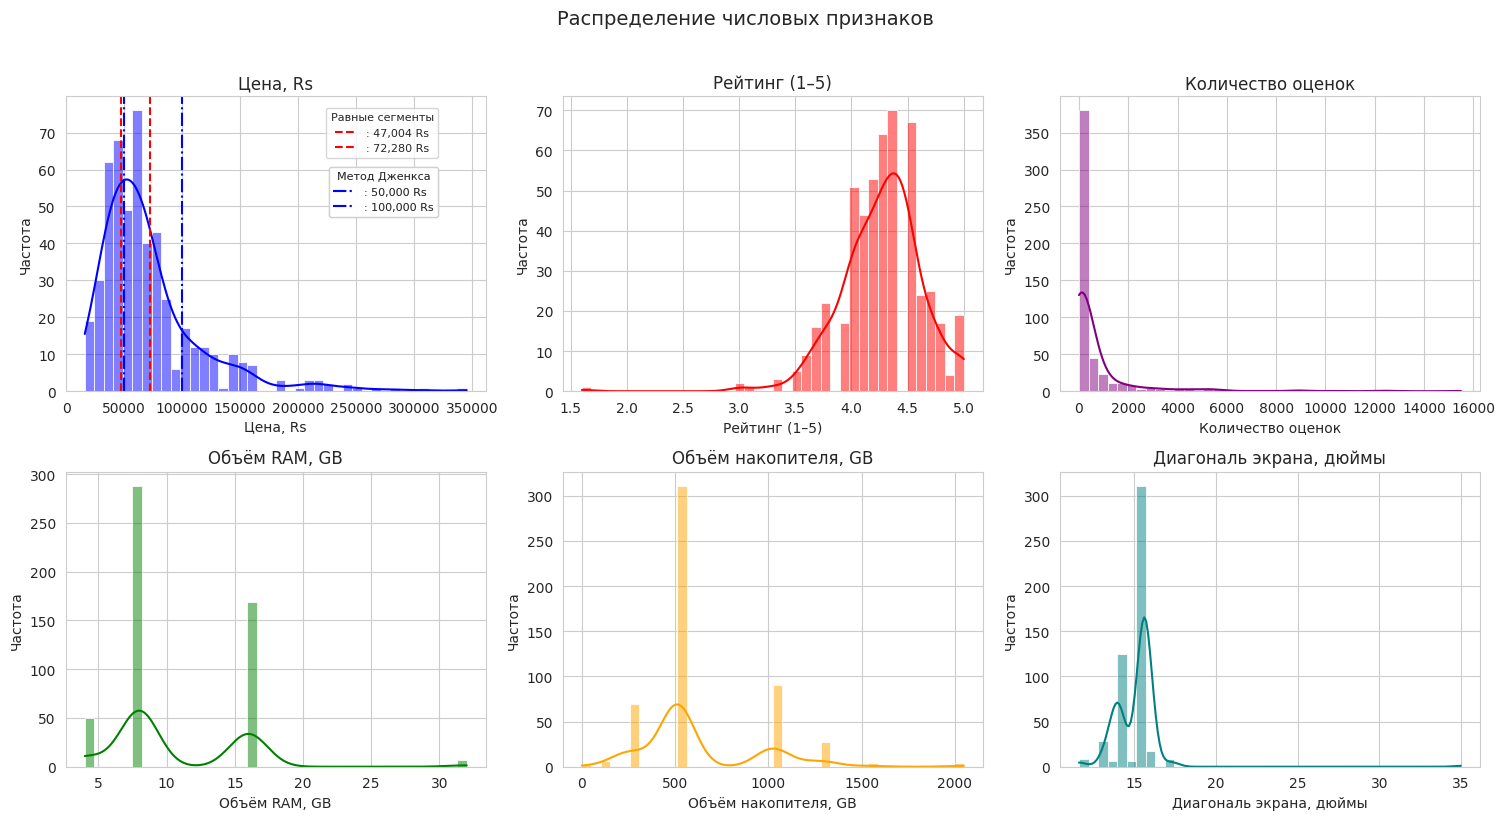

In [10]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
fig.suptitle('Распределение числовых признаков', fontsize=14, y=1.02)

plots = [
    ('price(in Rs.)', 'Цена, Rs', axes[0, 0], 'blue'),
    ('rating', 'Рейтинг (1–5)', axes[0, 1], 'red'),
    ('no_of_ratings', 'Количество оценок', axes[0, 2], 'purple'),
    ('ram_value', 'Объём RAM, GB', axes[1, 0], 'green'),
    ('storage_capacity', 'Объём накопителя, GB', axes[1, 1], 'orange'),
    ('display(in inch)', 'Диагональ экрана, дюймы', axes[1, 2], 'teal'),
]

for col, title, ax, color in plots:
    sns.histplot(df[col].dropna(), bins=40, ax=ax, color=color, kde=True)
    ax.set_title(title)
    ax.set_xlabel(title)
    ax.set_ylabel('Частота')

q33, q66 = df['price(in Rs.)'].quantile([0.33, 0.66]).values
ax_price = axes[0, 0]

ax_price.axvline(q33, color='red', linestyle='--', linewidth=1.5,
                 label=f'Квантиль 33%: {q33:,.0f} Rs')
ax_price.axvline(q66, color='red', linestyle='--', linewidth=1.5,
                 label=f'Квантиль 66%: {q66:,.0f} Rs')

jenks_bounds = [50_000, 100_000]

for b in jenks_bounds:
    ax_price.axvline(b, color='blue', linestyle='-.', linewidth=1.5,
                     label=f'Дженкс: {b:,.0f} Rs')

#leg1 = ax_price.legend(loc='upper right', fontsize=8, frameon=True,
#                       title='Квантили (33% / 66%)', title_fontsize=8)
#ax_price.add_artist(leg1)
leg1 = ax_price.legend(handles=[plt.Line2D([0], [0], color='red',
                                           linestyle='--', linewidth=1.5,
                                           label=f': {b:,.0f} Rs')
                                for b in [q33, q66]],
                       loc='upper right', bbox_to_anchor=(0.9, 0.98),
                       fontsize=8, frameon=True,
                       title='Равные сегменты', title_fontsize=8)
ax_price.add_artist(leg1)
leg2 = ax_price.legend(handles=[plt.Line2D([0], [0], color='blue',
                                           linestyle='-.', linewidth=1.5,
                                           label=f': {b:,.0f} Rs')
                                for b in jenks_bounds],
                       loc='upper right', bbox_to_anchor=(0.9, 0.78),
                       fontsize=8, frameon=True,
                       title='Метод Дженкса', title_fontsize=8)
ax_price.add_artist(leg2)

plt.tight_layout()
plt.show()

**Выводы по числовым признакам:**
1. **Рейтинг** основное количество моделей имеют оценку 4.0–4.7 — рынок конкурентный, низких оценок мало. В качестве критерия включения ноутбука в асортимент выбирем рейтинг ≥ 4.3 (медианное значение, включительно): модели с такой оценкой формируют верхнюю половину ассортимента.
2. **Количество оценок** — большинство моделей имеют десятки отзывов единичные модели имеют тысячи отзывов, отсекать модели с малым числом отзывов не целесоообразно.
3. **Цена** — большинство ноутбуков лежат в ценовом сегменте до 70k Rs, но есть и премиум-сегмент, разделение на ценовые сегменты разделением на равные по количеству области оказалось неудачным из-за слишком узкого среднего сегмента изменим их на более логичные выбранные методом Дженкса 50000 и 100000 рупий (отмечены синим на гистограмме) так что бы разница между сегментами была максимальной
4. **RAM**: доминируют 8 и 16 GB, есть 4 и 32 GB.
5. **Storage**: пики на 512 GB и 1024+ GB, есть гибридные HDD+SSD конфигурации.
6. **Диагональ экрана** — мода 15.6", есть 13–17".

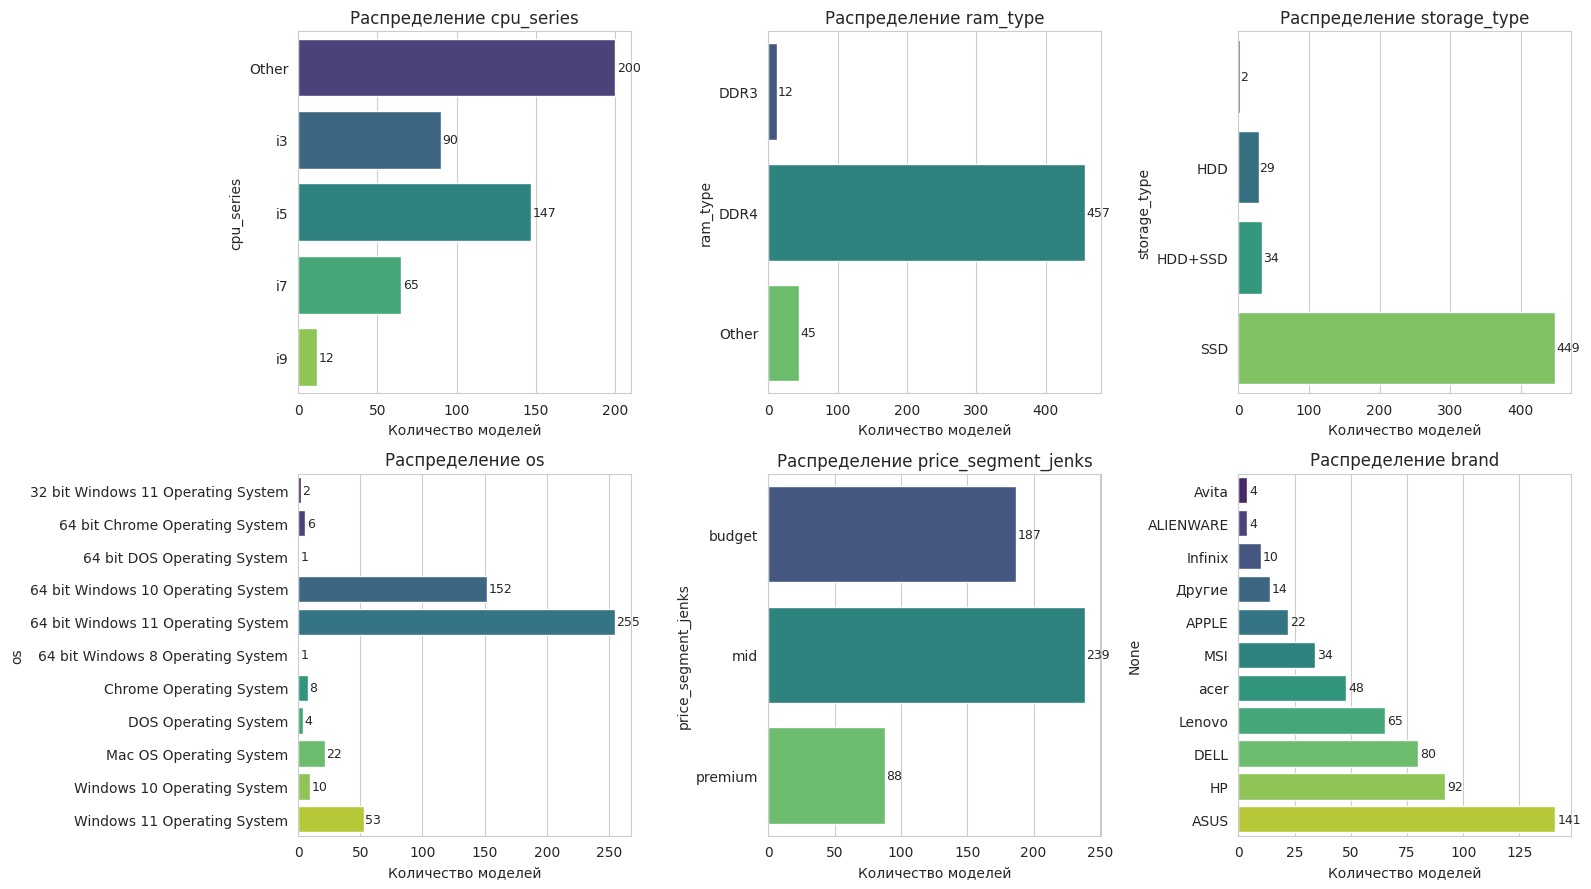

In [11]:
JENKS_BOUNDS = [50_000, 100_000]

def assign_jenks_segment(price):
    if price < JENKS_BOUNDS[0]:
        return 'budget'
    elif price < JENKS_BOUNDS[1]:
        return 'mid'
    return 'premium'

df['price_segment_jenks'] = df['price(in Rs.)'].apply(assign_jenks_segment)
df['price_segment_jenks'] = pd.Categorical(
    df['price_segment_jenks'],
    categories=['budget', 'mid', 'premium'],
    ordered=True,
)

cat_cols = ['cpu_series', 'ram_type', 'storage_type', 'os',
            'price_segment_jenks', 'brand']

fig, axes = plt.subplots(2, 3, figsize=(16, 9))
axes = axes.flatten()

for i, col in enumerate(cat_cols):
    counts = df[col].value_counts()
    if col == 'brand':
        top = counts.head(10)
        other = counts.iloc[10:].sum()
        if other > 0:
            top = pd.concat([top, pd.Series({'Другие': other})])
        counts = top.sort_values()

    elif col == 'price_segment_jenks':
        counts = counts.sort_index()

    else:
        counts = counts.sort_index()

    sns.barplot(x=counts.values, y=counts.index, ax=axes[i],
                hue=counts.index, palette='viridis', legend=False)
    axes[i].set_title(f'Распределение {col}')
    axes[i].set_xlabel('Количество моделей')
    for j, v in enumerate(counts.values):
        axes[i].text(v + 1, j, str(v), va='center', fontsize=9)

plt.tight_layout()
plt.show()

In [12]:
brand_stats = (df.groupby('brand')
               .agg(count=('rating', 'size'),
                    mean_rating=('rating', 'mean'),
                    median_price=('price(in Rs.)', 'median'))
               .query('count >= 10')
               .sort_values('count', ascending=False)
               .head(10))
brand_stats.round(2)

,count,mean_rating,median_price
brand,,,
ASUS,141,4.32,62490.0
HP,92,4.24,55495.0
DELL,80,4.14,57990.0
Lenovo,65,4.17,50990.0
acer,48,4.32,61994.5
MSI,34,4.41,78540.0
APPLE,22,4.67,128490.0
Infinix,10,4.19,40490.0


**Выводы по категориальным признакам:**

1. **CPU** доминируют Intel Core i5 и i3, i7 представлены в меньшей степени.
2. **RAM type** почти все модели имеют DDR4, DDR3 представленна значительно меньше.
3. **Storage** преобладает чистый SSD.
4. **OS** подавляющее большинство — Windows; macOS и Linux — на второй позиции.
5. **Price-сегменты**: budget сегмент составляет — 36.4% (187 моделей)
mid сегмент составляет — 46.5% (239 моделей
premium — 17.1% (88 моделей)
7. **Brand** основный рынок покрывают топ-10 брендов, остальные (Lenovo, HP, Dell, ASUS, Acer, MSI, Apple и др.) формируют длинный хвост, при этом среди топ-10 ни один бренд не доминирует с большим отрывом.

In [13]:

num_cols = ['price(in Rs.)', 'rating',
            'ram_value', 'storage_capacity', 'display(in inch)']

df_corr = df[num_cols].copy()

for col in ['brand', 'cpu_series', 'os']:
    te = df.groupby(col, observed=True)['rating'].transform('mean')
    df_corr[f'{col}_te'] = te

rename_map = {
    'price(in Rs.)':    'price',
    'rating':           'rating',
    'ram_value':        'ram_gb',
    'storage_capacity': 'storage_gb',
    'display(in inch)': 'display_inch',
    'brand_te':         'brand (TE)',
    'cpu_series_te':    'cpu_series (TE)',
    'os_te':            'os (TE)',
}
df_corr = df_corr.rename(columns=rename_map)

print(f"Признаков в матрице: {df_corr.shape[1]}")
print(f"Строк: {df_corr.shape[0]}")
print("\nСтолбцы:")
for i, c in enumerate(df_corr.columns, 1):
    print(f"  {i:2d}. {c}")

Признаков в матрице: 8
Строк: 514

Столбцы:
   1. price
   2. rating
   3. ram_gb
   4. storage_gb
   5. display_inch
   6. brand (TE)
   7. cpu_series (TE)
   8. os (TE)


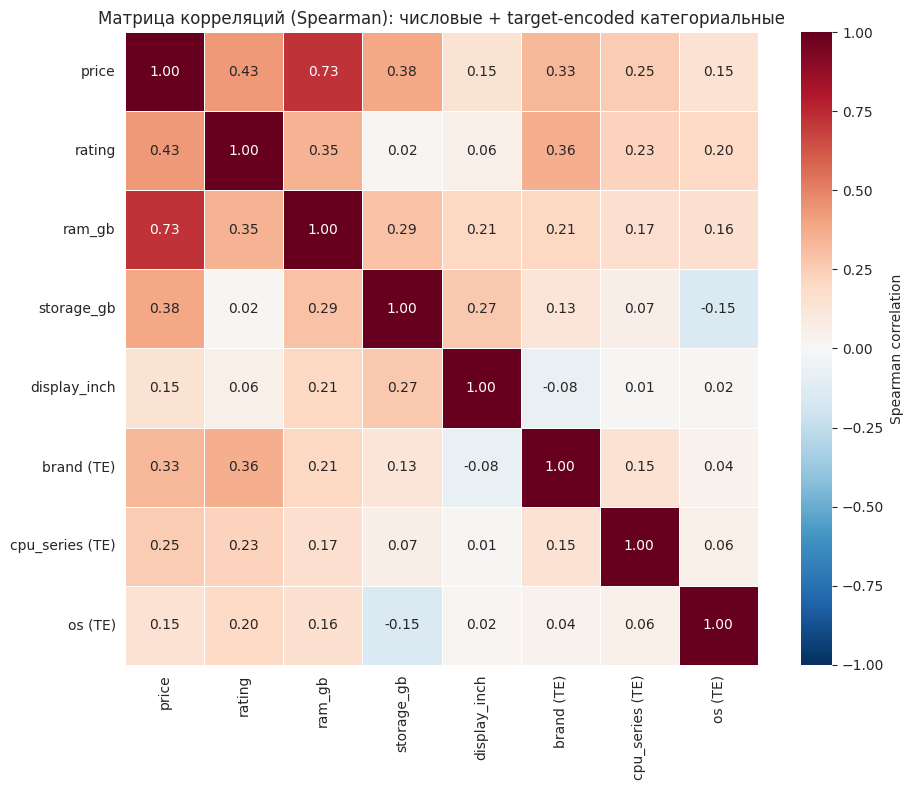

In [14]:
corr_matrix = df_corr.corr(method='spearman')

plt.figure(figsize=(10, 8))
sns.heatmap(
    corr_matrix,
    annot=True, fmt='.2f',
    cmap='RdBu_r', center=0,
    vmin=-1, vmax=1,
    square=True,
    linewidths=0.5,
    cbar_kws={'label': 'Spearman correlation'},
)
plt.title('Матрица корреляций (Spearman): числовые + target-encoded категориальные',
          fontsize=12)
plt.tight_layout()
plt.show()

Корреляции с rating (по убыванию |r|):
price              0.432
brand (TE)         0.364
ram_gb             0.347
cpu_series (TE)    0.228
os (TE)            0.195
display_inch       0.062
storage_gb         0.022


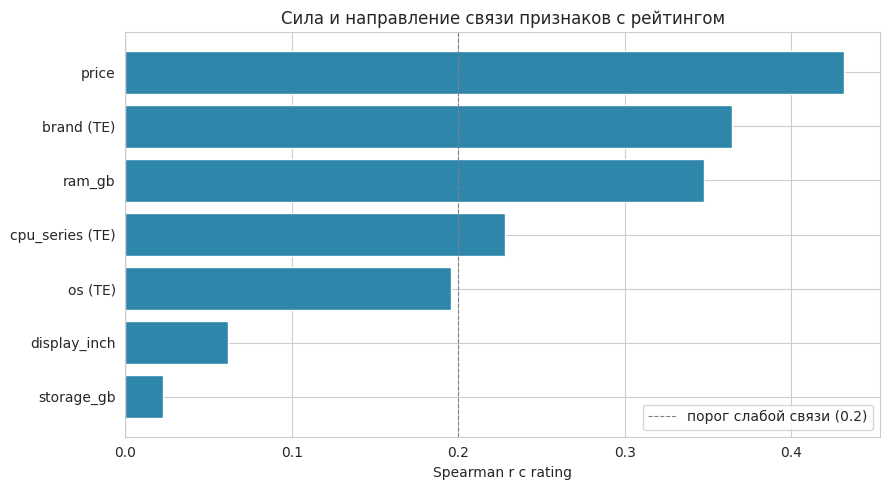

In [15]:
rating_corr = (corr_matrix['rating']
               .drop('rating')
               .sort_values(key=abs, ascending=False))

print("Корреляции с rating (по убыванию |r|):")
print(rating_corr.round(3).to_string())

plt.figure(figsize=(9, 5))
colors = ['#2E86AB' if v > 0 else '#C73E1D' for v in rating_corr.values]
plt.barh(rating_corr.index[::-1], rating_corr.values[::-1], color=colors[::-1])
plt.axvline(0, color='gray', linewidth=0.8)
plt.axvline(0.2, color='gray', linestyle='--', linewidth=0.8,
            label='порог слабой связи (0.2)')
plt.xlabel('Spearman r с rating')
plt.title('Сила и направление связи признаков с рейтингом')
plt.legend()
plt.tight_layout()
plt.show()

### Выводы корреляции рейтингом и числовых/ категориальных признаков

**Связи умеренные или слабые** |r| < 0.5

Ни один признак не объясняет рейтинг больше чем на ~19% дисперсии (`r² ≈ 0.19` для `price`).
Рейтинг остаётся многофакторным — оптимизировать ассортимент по одному признаку
нельзя. Но есть чёткий порядок силы связи, и он даёт практические выводы.

**Сильные связи (|r| ≥ 0.3) — две:**
- **`price` ↔ `rating` = 0.432** — самая сильная связь в матрице. Дорогие ноутбуки действительно получают систематически более высокие оценки.
- **`brand (TE)` ↔ `rating` = 0.364** — бренд объясняет значительную часть разброса. Репутация бренда — второй по силе предиктор рейтинга. Покупатели оценивают бренды по-разному, и разница между брендами устойчива.

**Умеренные связи (0.2 ≤ |r| < 0.3) — две:**
- **`ram_gb` ↔ `rating` = 0.347** — на границе с «сильными». Объём RAM — третий по силе предиктор: модели с большей памятью получают заметно более высокие оценки.
- **`cpu_series (TE)` ↔ `rating` = 0.228** — поколение/линейка CPU тоже вносит вклад, но в 1.5–2 раза слабее, чем RAM или бренд.

**Слабые связи (0.1 ≤ |r| < 0.2) — одна:**
- **`os (TE)` ↔ `rating` = 0.195** — слабое, но не нулевое влияние. Вероятно, за счёт Apple/macOS имеют более высокие оценки.

**Корреляция отсутствуюет (|r| < 0.1)**
- **`display_inch` 0.062** — размер экрана не связан с оценкой.
- **`storage_gb` 0.022** — Объём накопителя **не влияет на рейтинг**. Инсайт: наращивать ассортимент за счёт «больше памяти» нецелесообразно.

**Инстайты для бизнеса:**

1. **Цена и бренд — главные факторы рейтинга.** Среди всех числовых и категориальных признаков `price` (0.432) и `brand (TE)` (0.364) объясняют наибольшую часть вариации.Категорийному менеджеру стоит фокусироваться на этих двух измерениях: сегментация по цене + репутация бренда — а не на отдельных характеристиках.

2. **RAM важнее CPU и storage.** `ram_gb` (0.347) — единственная характеристика с заметной связью. `cpu_series` (0.228) — вдвое слабее, `storage_gb` (0.022) — практически ноль. Ассортиментная стратегия: «больше RAM за те же деньги» даст больше, чем «больше storage» или «более мощный CPU».

3. **Storage — «пустой» признак для рейтинга.** r = 0.022 — это статистический шум. Модели с 256 GB SSD и с 1 TB HDD+SSD получают одинаковые оценки. В карточке товара storage можно оставить как техническую информацию, но не делать на нём акцент в продвижении.

4. **Цена — не «наказание», а сигнал качества.** Контринтуитивный результат: более дорогие ноутбуки оцениваются **выше**, а не «строже». Возможные объяснения:
(а) дорогие SKU чаще покупают подготовленные пользователи,
(б) дорогие ноутбуки объективно лучше по совокупности характеристик, которые не сводятся к отдельным признакам.

5. **`display_inch` — не фактор выбора.** r = 0.062 — размер экрана не влияет на рейтинг. Покупатели оценивают ноутбук по другим критериям.

**Ограничения интерпретации:**
- **`price` и `brand (TE)` коррелированы** между собой: премиум-бренды обычно дороже.Разделить «эффект цены» и «эффект бренда» можно только регрессией с контролем на один из факторов (это следующая итерация анализа, вне текущего EDA).
- **Нет данных о продажах** → «связь с рейтингом» ≠ «связь с выручкой». Самые популярные SKU могут иметь посредственные оценки, но приносить основную выручку.

In [16]:
THRESHOLD_POINTS = [
    (0,        7.5),
    (120_000,  4.3 ** 2),
    (350_000,  4.3 ** 2),
    # (500_000, 20.0),
]
xs_pts = np.array([p[0] for p in THRESHOLD_POINTS], dtype=float)
ys_pts = np.array([p[1] for p in THRESHOLD_POINTS], dtype=float)
def threshold_y2(price):
    return np.interp(price, xs_pts, ys_pts)
df['rating_sq']    = df['rating'] ** 2
df['threshold_y2'] = threshold_y2(df['price(in Rs.)'].values)
df['under_curve'] = df['rating_sq'] < df['threshold_y2']
mask_under = df['under_curve']
mask_over  = ~mask_under
print("Точки порога:")
for x, y in THRESHOLD_POINTS:
    print(f"  x = {x:>10,.0f}   y = {y:.3f}")

Точки порога:
  x =          0   y = 7.500
  x =    120,000   y = 18.490
  x =    350,000   y = 18.490


In [17]:
from matplotlib.colors import to_rgb, to_hex
from sklearn.isotonic import IsotonicRegression
df['price'] = df['price(in Rs.)']
if 'mask_over' not in dir():
    if 'under_curve' in df.columns:
        mask_over = ~df['under_curve']
    else:
        raise NameError("mask_over non")
df_over = df.loc[mask_over].copy()
PRICE_WINDOW = 15_000
GRID_STEP    = PRICE_WINDOW / 4
MIN_COUNT    = 1
prices  = df_over['price(in Rs.)'].to_numpy()
ratings = df_over['rating'].to_numpy()
grid = np.arange(df['price(in Rs.)'].min(),
                 df['price(in Rs.)'].max() + GRID_STEP,
                 GRID_STEP)
rows = []
for c in grid:
    m = (prices >= c - PRICE_WINDOW) & (prices <= c + PRICE_WINDOW)
    n = int(m.sum())
    if n < MIN_COUNT:
        continue
    rows.append({
        'price_center':    c,
        'price_lo':        c - PRICE_WINDOW,
        'price_hi':        c + PRICE_WINDOW,
        'rating_mean_raw': ratings[m].mean(),
        'count':           n,
    })
mean_rating_by_price = (
    pd.DataFrame(rows)
      .sort_values('price_center')
      .reset_index(drop=True)
)
iso = IsotonicRegression(increasing=True, out_of_bounds='clip')
mean_rating_by_price['rating_mean_iso'] = iso.fit_transform(
    mean_rating_by_price['price_center'],
    mean_rating_by_price['rating_mean_raw'],
)
print(f"\nМоделей в окне: "
      f"min={mean_rating_by_price['count'].min()}, "
      f"median={int(mean_rating_by_price['count'].median())}, "
      f"max={mean_rating_by_price['count'].max()}")


Моделей в окне: min=1, median=7, max=235


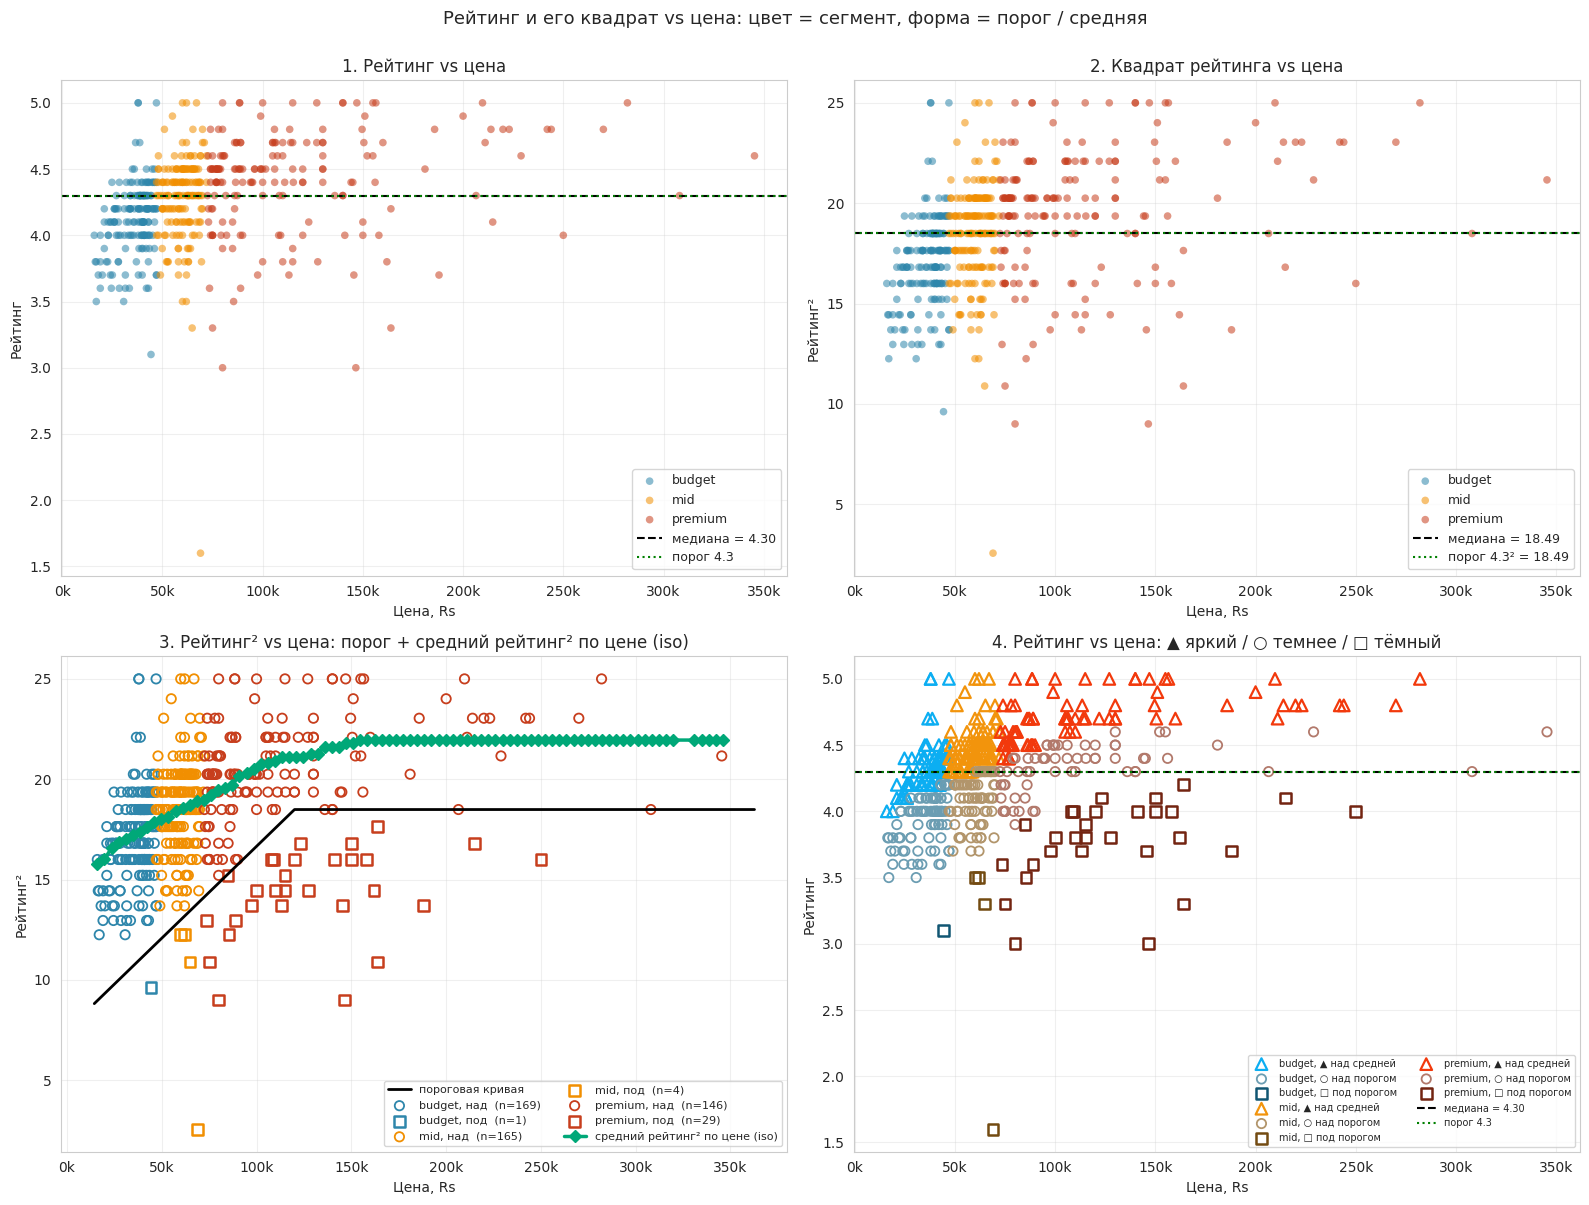

In [18]:
import colorsys
import matplotlib.ticker as mtick
if 'rating_sq' not in df.columns:
    df['rating_sq'] = df['rating'] ** 2
if 'mask_under' not in dir() and 'under_curve' in df.columns:
    mask_under = df['under_curve']
if 'mask_over' not in dir():
    mask_over = ~mask_under
SEG_COLORS = {'budget': '#2E86AB', 'mid': '#F18F01', 'premium': '#C73E1D'}
SEG_ORDER  = ['budget', 'mid', 'premium']


def shade(color_hex, v, s):
    r, g, b = to_rgb(color_hex)
    h, _, _ = colorsys.rgb_to_hsv(r, g, b)
    r, g, b = colorsys.hsv_to_rgb(h, s, v)
    return to_hex((r, g, b))

COLOR_BY_SHAPE = {
    seg: {
        'tri':  shade(base, v=0.95, s=0.95),
        'circ': shade(base, v=0.70, s=0.40),
        'sq':   shade(base, v=0.45, s=0.85),
    }
    for seg, base in SEG_COLORS.items()
}

mean_curve_at_price = np.interp(
    df['price(in Rs.)'].values,
    mean_rating_by_price['price_center'].values,
    (mean_rating_by_price['rating_mean_iso'] ** 2).values,
)
df['above_mean'] = df['rating_sq'].values > mean_curve_at_price

fig, axes = plt.subplots(2, 2, figsize=(16, 12))
ax1, ax2, ax3, ax4 = axes.flatten()

for ax, ycol, ylabel, title, hline in [
    (ax1, 'rating',    'Рейтинг',  '1. Рейтинг vs цена',
     ('порог 4.3', 4.3)),
    (ax2, 'rating_sq', 'Рейтинг²', '2. Квадрат рейтинга vs цена',
     ('порог 4.3² = 18.49', 4.3 ** 2)),
]:
    for seg, color in SEG_COLORS.items():
        sub = df[df['price_segment'] == seg]
        ax.scatter(sub['price(in Rs.)'], sub[ycol],
                   s=30, alpha=0.55, color=color, label=seg, edgecolors='none')
    ax.axhline(df[ycol].median(), color='black', linestyle='--', linewidth=1.5,
               label=f"медиана = {df[ycol].median():.2f}")
    ax.axhline(hline[1], color='green', linestyle=':', linewidth=1.5,
               label=hline[0])
    ax.set_xlabel('Цена, Rs'); ax.set_ylabel(ylabel); ax.set_title(title)
    ax.xaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f'{v/1000:.0f}k'))
    ax.legend(loc='lower right', fontsize=9)
    ax.grid(alpha=0.3)

x_line = np.linspace(max(0, df['price(in Rs.)'].min() * 0.9),
                     df['price(in Rs.)'].max() * 1.05, 400)

ax3.plot(x_line, threshold_y2(x_line), color='black', linewidth=2,
         label='пороговая кривая')

for seg in SEG_ORDER:
    color = SEG_COLORS[seg]
    sub_under = df[(df['price_segment'] == seg) & mask_under]
    sub_over  = df[(df['price_segment'] == seg) & mask_over]
    ax3.scatter(sub_over['price(in Rs.)'], sub_over['rating_sq'],
                s=45, facecolors='none', edgecolors=color,
                linewidths=1.3, marker='o',
                label=f'{seg}, над  (n={len(sub_over)})')
    ax3.scatter(sub_under['price(in Rs.)'], sub_under['rating_sq'],
                s=60, facecolors='none', edgecolors=color,
                linewidths=1.8, marker='s',
                label=f'{seg}, под  (n={len(sub_under)})')

ax3.plot(mean_rating_by_price['price_center'],
         mean_rating_by_price['rating_mean_iso'] ** 2,
         color='#00A878', linewidth=2.5, marker='D', markersize=6,
         label='средний рейтинг² по цене (iso)')

ax3.set_xlabel('Цена, Rs'); ax3.set_ylabel('Рейтинг²')
ax3.set_title('3. Рейтинг² vs цена: порог + средний рейтинг² по цене (iso)')
ax3.xaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f'{v/1000:.0f}k'))
ax3.legend(loc='lower right', fontsize=8, ncol=2)
ax3.grid(alpha=0.3)

for seg in SEG_ORDER:
    mask_seg = df['price_segment'] == seg
    c_tri  = COLOR_BY_SHAPE[seg]['tri']
    c_circ = COLOR_BY_SHAPE[seg]['circ']
    c_sq   = COLOR_BY_SHAPE[seg]['sq']

    m = mask_seg & df['above_mean']
    ax4.scatter(df.loc[m, 'price(in Rs.)'], df.loc[m, 'rating'],
                s=70, facecolors='none', edgecolors=c_tri,
                linewidths=1.6, marker='^',
                label=f'{seg}, ▲ над средней')

    m = mask_seg & mask_over & ~df['above_mean']
    ax4.scatter(df.loc[m, 'price(in Rs.)'], df.loc[m, 'rating'],
                s=45, facecolors='none', edgecolors=c_circ,
                linewidths=1.3, marker='o',
                label=f'{seg}, ○ над порогом')

    m = mask_seg & mask_under & ~df['above_mean']
    ax4.scatter(df.loc[m, 'price(in Rs.)'], df.loc[m, 'rating'],
                s=60, facecolors='none', edgecolors=c_sq,
                linewidths=1.8, marker='s',
                label=f'{seg}, □ под порогом')

ax4.axhline(df['rating'].median(), color='black', linestyle='--', linewidth=1.5,
            label=f"медиана = {df['rating'].median():.2f}")
ax4.axhline(4.3, color='green', linestyle=':', linewidth=1.5, label='порог 4.3')

ax4.set_xlabel('Цена, Rs'); ax4.set_ylabel('Рейтинг')
ax4.set_title('4. Рейтинг vs цена: ▲ яркий / ○ темнее / □ тёмный')
ax4.xaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f'{v/1000:.0f}k'))
ax4.legend(loc='lower right', fontsize=7, ncol=2)
ax4.grid(alpha=0.3)

plt.suptitle('Рейтинг и его квадрат vs цена: цвет = сегмент, форма = порог / средняя',
             fontsize=13, y=1.00)
plt.tight_layout()
plt.show()

## Выводы по сегментации и логика маркировки ассортимента

**Логика разделения моделей (на основе рейтинга и цены):**
Порог рейтинга для premium сегмента выбран как 4.3 (медиана рынка) и изотоническую кривая для mid и budget сегмента.
1.  **▲ Треугольники "Хорошая цена"** — рейтинг > 4.3, и модель находится **выше** средней кривой для своей цены. Эти модели **однозначно рекомендуются к включению** и могут быть дополнительно отмечены в асортименте как **хорошая цена**.
2.  **○ Кружки ("Просто рекомендуются")** — рейтинг > 4.3 для premium, но модель находится **ниже** средней кривой для своей цены. **Рекомендуются к включению** для заполнения ассортиментной матрицы.
3.  **□ Квадраты (не рекомендованы)** — рейтинг < 4.3. Плохое соотношение цены и качества. Рекомендуется **исключить из ассортимента.**

**Ключевые драйверы рейтинга (Инсайты):**
*   **Цена (r=0.43)** и **Бренд (r=0.36)** — главные факторы. Дорогие и премиальные бренды оцениваются выше.
*   **RAM (r=0.35)** — самая важная техническая характеристика. Больше памяти за те же деньги = выше рейтинг.
*   **Процессор (r=0.23)** — умеренно влияет.
*   **Накопитель (r=0.02)** и **Диагональ экрана (r=0.06)** — **не влияют на рейтинг**. На объеме SSD не стоит делать акцент в продвижении.

**Принцип разбиения по цене (Метод Дженкса):**
*   **Budget (< 50 000 Rs)** — 36% рынка. Борьба за цену.
*   **Mid (50 000 – 100 000 Rs)** — 46% рынка. Лучшее соотношение цена/качество.
*   **Premium (> 100 000 Rs)** — 17% рынка. Топовые бренды и высокие оценки.

**Средние рейтинги для групп рассчит динамически:**
*   **Хорошая цена (▲)**: Средний рейтинг ~ 4.60
*   **Рекомендуемые (○)**: Средний рейтинг ~ 4.40
*(Точные значения преведены на дашборде ниже).*

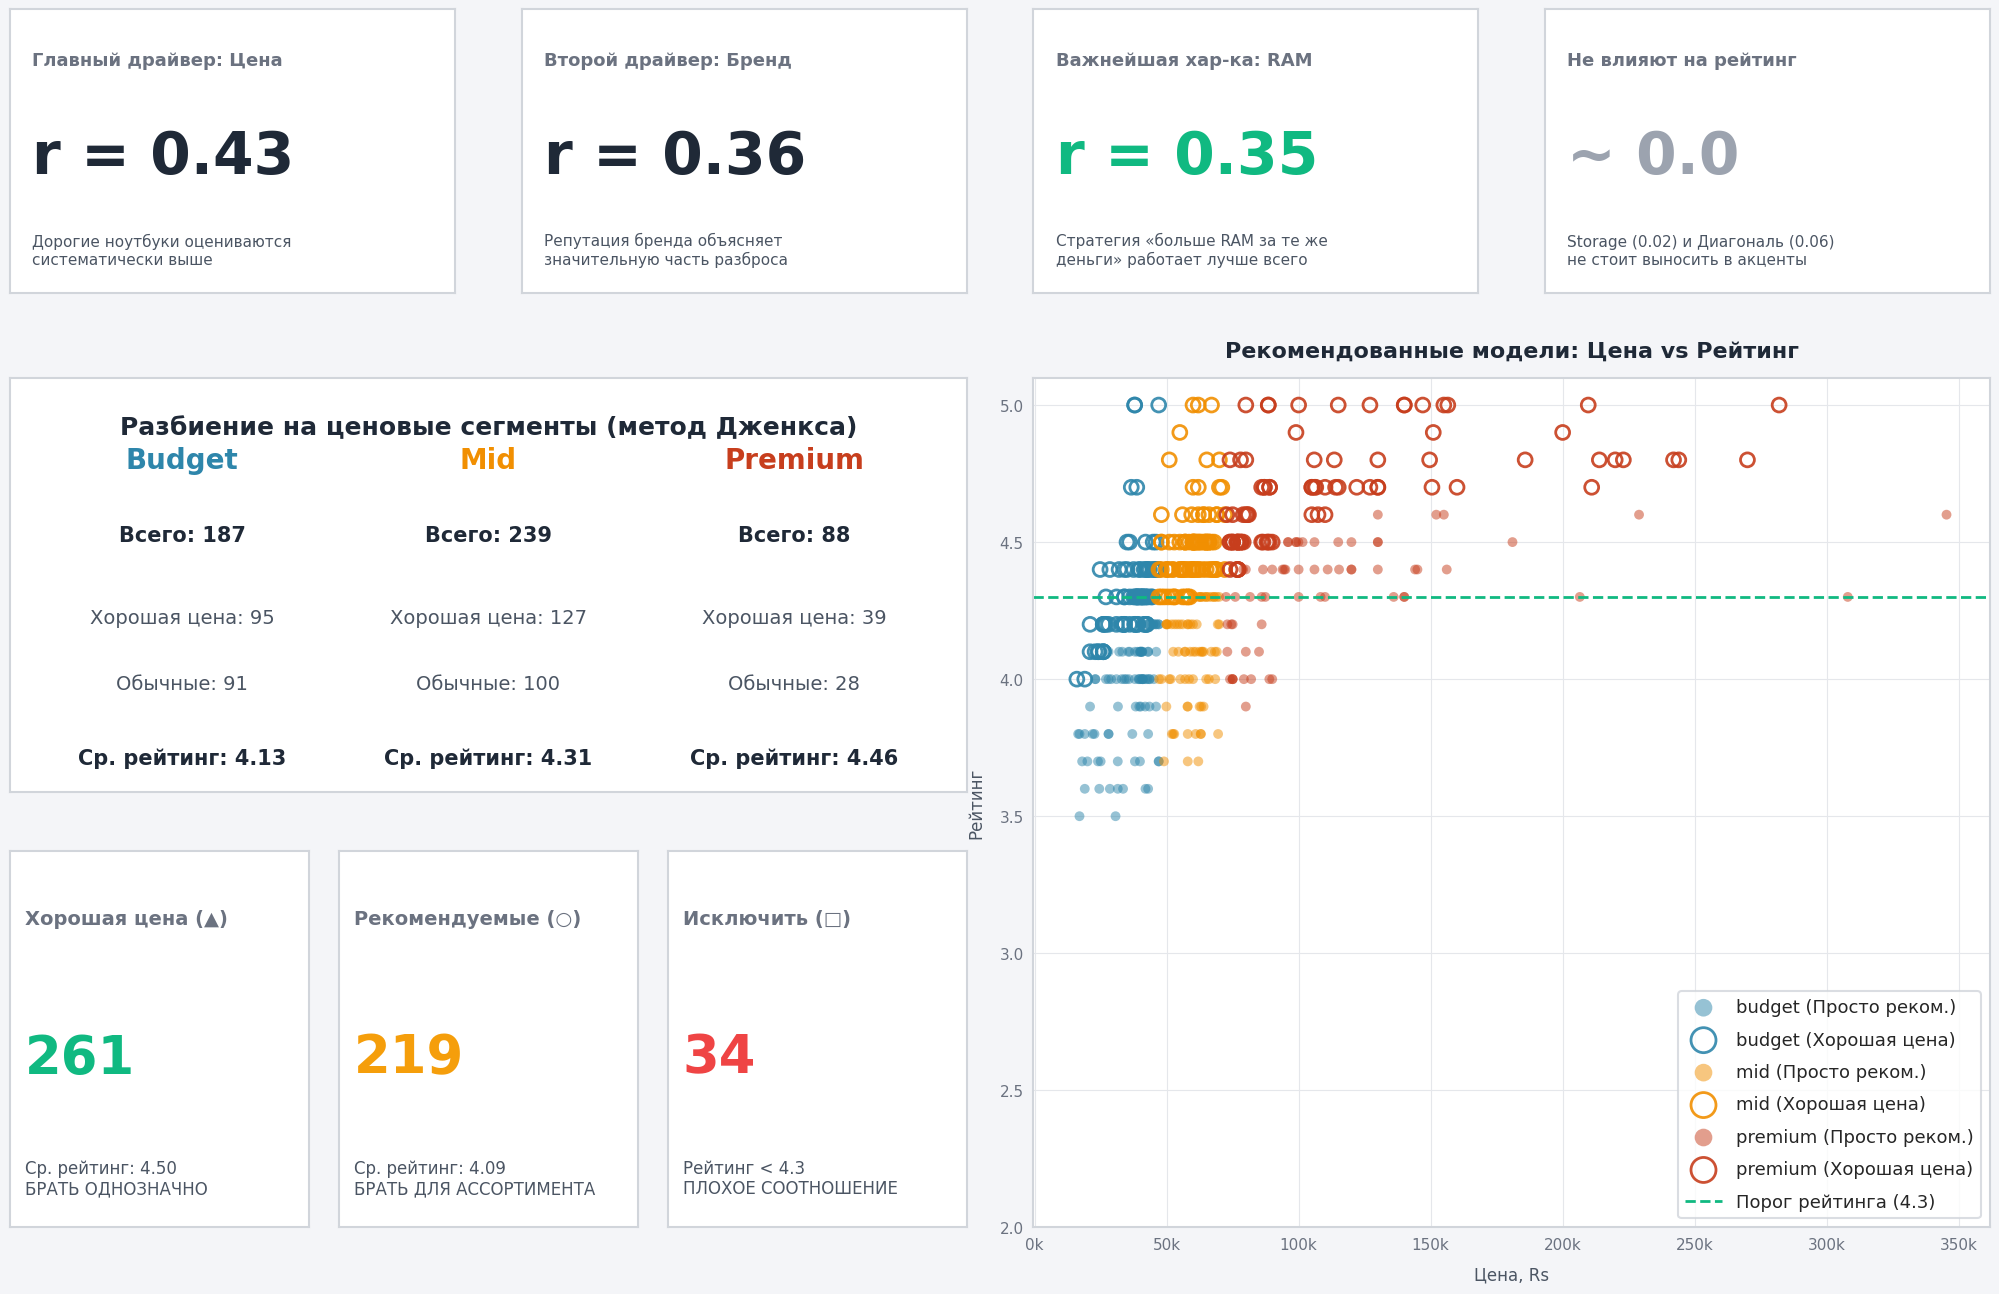

In [19]:
import matplotlib.gridspec as gridspec
included_df = df[mask_over].copy()
good_price_df = included_df[included_df['above_mean']]
regular_df = included_df[~included_df['above_mean']]
excluded_df = df[mask_under].copy()

mean_good = good_price_df['rating'].mean()
mean_reg = regular_df['rating'].mean()
count_good = len(good_price_df)
count_reg = len(regular_df)
count_exc = len(excluded_df)

seg_stats = []
for seg in ['budget', 'mid', 'premium']:
    seg_df = df[df['price_segment_jenks'] == seg]
    total = len(seg_df)
    seg_inc = included_df[included_df['price_segment_jenks'] == seg]
    good = len(seg_inc[seg_inc['above_mean'] == True])
    reg = len(seg_inc[seg_inc['above_mean'] == False])
    mean_rat = seg_df['rating'].mean()
    seg_stats.append({'seg': seg, 'total': total, 'good': good, 'reg': reg, 'mean': mean_rat})

fig = plt.figure(figsize=(22, 14), facecolor='#F4F5F8')
gs = gridspec.GridSpec(2, 4, height_ratios=[1, 3], hspace=0.15, wspace=0.15)
fig.subplots_adjust(top=0.92, bottom=0.05, left=0.05, right=0.95)

def draw_card(ax, title, value, description, value_color='#1F2937', is_small=False):
    ax.set_facecolor('#FFFFFF')
    for spine in ax.spines.values():
        spine.set_color('#D1D5DB')
        spine.set_linewidth(1.5)
    ax.set_xticks([])
    ax.set_yticks([])

    if is_small:
        val_size, title_size, desc_size = 38, 14, 12
        y_val, y_desc = 0.45, 0.13
    else:
        val_size, title_size, desc_size = 42, 13, 11
        y_val, y_desc = 0.48, 0.15

    ax.text(0.05, 0.82, title, fontsize=title_size, color='#6B7280', ha='left', va='center', fontweight='bold', transform=ax.transAxes)
    ax.text(0.05, y_val, str(value), fontsize=val_size, color=value_color, ha='left', va='center', fontweight='bold', transform=ax.transAxes)
    ax.text(0.05, y_desc, description, fontsize=desc_size, color='#4B5563', ha='left', va='center', transform=ax.transAxes)

ax1 = fig.add_subplot(gs[0, 0])
draw_card(ax1, "Главный драйвер: Цена", "r = 0.43", "Дорогие ноутбуки оцениваются\nсистематически выше")

ax2 = fig.add_subplot(gs[0, 1])
draw_card(ax2, "Второй драйвер: Бренд", "r = 0.36", "Репутация бренда объясняет\nзначительную часть разброса")

ax3 = fig.add_subplot(gs[0, 2])
draw_card(ax3, "Важнейшая хар-ка: RAM", "r = 0.35", "Стратегия «больше RAM за те же\nденьги» работает лучше всего", value_color='#10B981')

ax4 = fig.add_subplot(gs[0, 3])
draw_card(ax4, "Не влияют на рейтинг", "~ 0.0", "Storage (0.02) и Диагональ (0.06)\nне стоит выносить в акценты", value_color='#9CA3AF')

gs_left = gridspec.GridSpecFromSubplotSpec(2, 3, subplot_spec=gs[1, 0:2], height_ratios=[1.1, 1], hspace=0.15, wspace=0.1)
ax_jenks = fig.add_subplot(gs_left[0, :])
ax_jenks.set_facecolor('#FFFFFF')
for spine in ax_jenks.spines.values():
    spine.set_color('#D1D5DB')
    spine.set_linewidth(1.5)
ax_jenks.set_xticks([])
ax_jenks.set_yticks([])

ax_jenks.text(0.5, 0.88, "Разбиение на ценовые сегменты (метод Дженкса)", ha='center', va='center', fontsize=18, fontweight='bold', color='#1F2937')

x_positions = [0.18, 0.5, 0.82]
for i, stat in enumerate(seg_stats):
    color = SEG_COLORS[stat['seg']]
    seg_name = stat['seg'].capitalize()
    ax_jenks.text(x_positions[i], 0.80, seg_name, ha='center', va='center', fontsize=20, fontweight='bold', color=color)
    ax_jenks.text(x_positions[i], 0.62, f"Всего: {stat['total']}", ha='center', va='center', fontsize=15, color='#1F2937', fontweight='bold')
    ax_jenks.text(x_positions[i], 0.42, f"Хорошая цена: {stat['good']}", ha='center', va='center', fontsize=14, color='#4B5563')
    ax_jenks.text(x_positions[i], 0.26, f"Обычные: {stat['reg']}", ha='center', va='center', fontsize=14, color='#4B5563')
    ax_jenks.text(x_positions[i], 0.08, f"Ср. рейтинг: {stat['mean']:.2f}", ha='center', va='center', fontsize=15, color='#1F2937', fontweight='bold')

ax_seg1 = fig.add_subplot(gs_left[1, 0])
draw_card(ax_seg1, "Хорошая цена (▲)", count_good, f"Ср. рейтинг: {mean_good:.2f}\nБРАТЬ ОДНОЗНАЧНО", value_color='#10B981', is_small=True)

ax_seg2 = fig.add_subplot(gs_left[1, 1])
draw_card(ax_seg2, "Рекомендуемые (○)", count_reg, f"Ср. рейтинг: {mean_reg:.2f}\nБРАТЬ ДЛЯ АССОРТИМЕНТА", value_color='#F59E0B', is_small=True)

ax_seg3 = fig.add_subplot(gs_left[1, 2])
draw_card(ax_seg3, "Исключить (□)", count_exc, "Рейтинг < 4.3\nПЛОХОЕ СООТНОШЕНИЕ", value_color='#EF4444', is_small=True)

ax_scatter = fig.add_subplot(gs[1, 2:])
ax_scatter.set_facecolor('#FFFFFF')
for spine in ax_scatter.spines.values():
    spine.set_color('#D1D5DB')
    spine.set_linewidth(1.5)

for seg in ['budget', 'mid', 'premium']:
    color = SEG_COLORS[seg]

    reg_sub = regular_df[regular_df['price_segment'] == seg]
    ax_scatter.scatter(
        reg_sub['price(in Rs.)'], reg_sub['rating'],
        s=50, color=color, alpha=0.5, edgecolors='none',
        label=f'{seg} (Просто реком.)'
    )

    good_sub = good_price_df[good_price_df['price_segment'] == seg]
    ax_scatter.scatter(
        good_sub['price(in Rs.)'], good_sub['rating'],
        s=100, facecolors='none', edgecolors=color, linewidths=2.0, alpha=0.9,
        label=f'{seg} (Хорошая цена)'
    )

ax_scatter.axhline(4.3, color='#10B981', linestyle='--', linewidth=2, label='Порог рейтинга (4.3)')

ax_scatter.set_title('Рекомендованные модели: Цена vs Рейтинг', fontsize=16, fontweight='bold', color='#1F2937', pad=15)
ax_scatter.set_xlabel('Цена, Rs', fontsize=12, color='#4B5563', labelpad=10)
ax_scatter.set_ylabel('Рейтинг', fontsize=12, color='#4B5563', labelpad=10)
ax_scatter.xaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f'{v/1000:.0f}k'))
ax_scatter.tick_params(colors='#6B7280', labelsize=11)
ax_scatter.set_ylim(2, 5.1)
ax_scatter.grid(color='#E5E7EB', linestyle='-', linewidth=0.8)

legend = ax_scatter.legend(
    frameon=True, facecolor='#FFFFFF', edgecolor='#D1D5DB',
    fontsize=13, loc='lower right', markerscale=1.8, labelspacing=0.8
)
legend.get_frame().set_linewidth(1.5)

plt.show()